# 01 · Chargement, exploration, premiers graphiques (jalon M1)

**Données :** comptages routiers permanents de la Ville de Paris, 3 axes : `Bd_Richard_Lenoir`, `Av_Ledru_Rollin`, `Bd_Gal_Martial_Valin`, du 1er mars au 31 août 2026.

**Objectif :** charger les données par *chunks* avec les bons types, les explorer, et produire 3 graphiques commentés.

> **Pour réviser** : chaque section explique *pourquoi* on fait l'étape, pas seulement *comment*.

## 0. Prérequis
Lancer une fois `python download_data.py` (les données vont dans `data/raw/`, ignoré par Git).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

CHEMIN = Path("data/raw/comptages.csv")
print(f"{CHEMIN.stat().st_size / 1e6:.1f} Mo")

14.6 Mo


## 1. Regarder le fichier AVANT de le charger
Règle n°1 : on ne devine pas le format d'un CSV, on le lit en texte brut. On cherche le séparateur, l'encodage, le format des dates.

In [2]:
with open(CHEMIN, encoding="utf-8-sig") as f:
    for _ in range(4):
        print(f.readline().rstrip())

iu_ac;libelle;t_1h;q;k;etat_trafic;iu_nd_amont;libelle_nd_amont;iu_nd_aval;libelle_nd_aval;etat_barre
4664;Av_Ledru_Rollin;2026-08-31T23:00:00+00:00;153.0;1.21723;Fluide;2481;Rue_Fbg_St_Antoine-Av_L_Rollin;2483;Av_Ledru_Rollin-Charonne;Ouvert
4670;Av_Ledru_Rollin;2026-08-31T23:00:00+00:00;153.0;0.43111;Fluide;2483;Av_Ledru_Rollin-Charonne;2487;Av_Ledru_Rollin-Basfroi;Ouvert
1314;Bd_Richard_Lenoir;2026-08-31T23:00:00+00:00;180.0;0.90333;Fluide;722;Bd_Richard_Lenoir-St_Sebastien;721;Bd_Richard_Lenoir-Pelee-Moufle;Ouvert


On voit que le séparateur est `;` (pas `,`). Le fichier commence aussi par un caractère invisible, le **BOM** (`\ufeff`) : sans `encoding="utf-8-sig"`, le nom de la première colonne serait `\ufeffiu_ac`.

In [3]:
naif = pd.read_csv(CHEMIN, nrows=5)               # tentative naïve
print(naif.shape)                                  # 1 seule colonne = mauvais séparateur
apercu = pd.read_csv(CHEMIN, sep=";", encoding="utf-8-sig", nrows=5)
print(apercu.columns.tolist())
apercu

(5, 1)
['iu_ac', 'libelle', 't_1h', 'q', 'k', 'etat_trafic', 'iu_nd_amont', 'libelle_nd_amont', 'iu_nd_aval', 'libelle_nd_aval', 'etat_barre']


,iu_ac,libelle,t_1h,q,k,etat_trafic,iu_nd_amont,libelle_nd_amont,iu_nd_aval,libelle_nd_aval,etat_barre
0,4664,Av_Ledru_Rollin,2026-08-31T23:00:00+00:00,153.0,1.21723,Fluide,2481,Rue_Fbg_St_Antoine-Av_L_Rollin,2483,Av_Ledru_Rollin-Charonne,Ouvert
1,4670,Av_Ledru_Rollin,2026-08-31T23:00:00+00:00,153.0,0.43111,Fluide,2483,Av_Ledru_Rollin-Charonne,2487,Av_Ledru_Rollin-Basfroi,Ouvert
2,1314,Bd_Richard_Lenoir,2026-08-31T23:00:00+00:00,180.0,0.90333,Fluide,722,Bd_Richard_Lenoir-St_Sebastien,721,Bd_Richard_Lenoir-Pelee-Moufle,Ouvert
3,1317,Bd_Richard_Lenoir,2026-08-31T23:00:00+00:00,83.0,0.25056,Fluide,721,Bd_Richard_Lenoir-Pelee-Moufle,722,Bd_Richard_Lenoir-St_Sebastien,Ouvert
4,1319,Bd_Richard_Lenoir,2026-08-31T23:00:00+00:00,83.0,0.26889,Fluide,722,Bd_Richard_Lenoir-St_Sebastien,723,Bd_Richard_Lenoir-Chemin_Vert,Ouvert


## 2. Chargement par *chunks* avec les bons types
- **Chunks** : on lit le fichier par morceaux de 50 000 lignes. Ici on les recolle (le fichier est petit), mais la même boucle permettrait de filtrer ou d'agréger *pendant* la lecture sur les 30 millions de lignes de la base complète.
- **Types** : `iu_ac`, `iu_nd_amont`, `iu_nd_aval` sont des **codes** (identifiants), pas des quantités : on ne fait jamais de moyenne dessus, et un identifiant numérique pourrait perdre ses zéros initiaux. Les colonnes à peu de valeurs différentes (`etat_trafic`, `etat_barre`, `libelle`) passent en `category` : moins de mémoire, tri plus clair.
- `t_1h` reste du texte pour l'instant ; on le convertit en M2.

In [4]:
TYPES = {
    "iu_ac": "string", "iu_nd_amont": "string", "iu_nd_aval": "string",
    "libelle_nd_amont": "string", "libelle_nd_aval": "string",
    "libelle": "category", "etat_trafic": "category", "etat_barre": "category",
}

morceaux = []
for i, chunk in enumerate(pd.read_csv(CHEMIN, sep=";", encoding="utf-8-sig",
                                      dtype=TYPES, chunksize=50_000)):
    morceaux.append(chunk)
print(f"{i + 1} chunks lus")

df = pd.concat(morceaux, ignore_index=True)
print(df.shape)
print(f"Mémoire : {df.memory_usage(deep=True).sum() / 1e6:.1f} Mo")

3 chunks lus
(104736, 11)
Mémoire : 47.5 Mo


## 3. Exploration

In [5]:
df.head()

,iu_ac,libelle,t_1h,q,k,etat_trafic,iu_nd_amont,libelle_nd_amont,iu_nd_aval,libelle_nd_aval,etat_barre
0,4664,Av_Ledru_Rollin,2026-08-31T23:00:00+00:00,153.0,1.21723,Fluide,2481,Rue_Fbg_St_Antoine-Av_L_Rollin,2483,Av_Ledru_Rollin-Charonne,Ouvert
1,4670,Av_Ledru_Rollin,2026-08-31T23:00:00+00:00,153.0,0.43111,Fluide,2483,Av_Ledru_Rollin-Charonne,2487,Av_Ledru_Rollin-Basfroi,Ouvert
2,1314,Bd_Richard_Lenoir,2026-08-31T23:00:00+00:00,180.0,0.90333,Fluide,722,Bd_Richard_Lenoir-St_Sebastien,721,Bd_Richard_Lenoir-Pelee-Moufle,Ouvert
3,1317,Bd_Richard_Lenoir,2026-08-31T23:00:00+00:00,83.0,0.25056,Fluide,721,Bd_Richard_Lenoir-Pelee-Moufle,722,Bd_Richard_Lenoir-St_Sebastien,Ouvert
4,1319,Bd_Richard_Lenoir,2026-08-31T23:00:00+00:00,83.0,0.26889,Fluide,722,Bd_Richard_Lenoir-St_Sebastien,723,Bd_Richard_Lenoir-Chemin_Vert,Ouvert


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104736 entries, 0 to 104735
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype   
---  ------            --------------   -----   
 0   iu_ac             104736 non-null  string  
 1   libelle           104736 non-null  category
 2   t_1h              104736 non-null  object  
 3   q                 101995 non-null  float64 
 4   k                 102565 non-null  float64 
 5   etat_trafic       104736 non-null  category
 6   iu_nd_amont       104736 non-null  string  
 7   libelle_nd_amont  104736 non-null  string  
 8   iu_nd_aval        104736 non-null  string  
 9   libelle_nd_aval   104736 non-null  string  
 10  etat_barre        104736 non-null  object  
dtypes: category(2), float64(2), object(2), string(5)
memory usage: 7.4+ MB


In [7]:
# q = débit horaire (véhicules/heure), k = taux d'occupation (%)
df[["q", "k"]].describe().round(1)

,q,k
count,101995.0,102565.0
mean,271.8,4.2
std,161.5,8.5
min,0.0,0.0
25%,154.0,0.9
50%,236.0,2.1
75%,384.0,3.9
max,5479.0,93.2


In [8]:
print("Médiane de q :", df["q"].median(), "| moyenne :", round(df["q"].mean(), 1), "| max :", df["q"].max())

Médiane de q : 236.0 | moyenne : 271.8 | max : 5478.95


Si la moyenne est très différente de la médiane, ou si le maximum est très loin du 75e percentile, la distribution a une **longue queue** ou contient des **valeurs aberrantes** : on y revient en M3.

In [9]:
manquants = df.isna().mean().sort_values(ascending=False).round(3)
manquants[manquants > 0]

q    0.026
k    0.021
dtype: float64

In [10]:
for col in ["etat_trafic", "etat_barre"]:
    print(df[col].value_counts(normalize=True, dropna=False).round(3), "\n")

etat_trafic
Fluide        0.928
Pré-saturé    0.027
Inconnu       0.021
Saturé        0.014
Bloqué        0.010
Name: proportion, dtype: float64 

etat_barre
Ouvert      0.98
Invalide    0.02
Barré       0.00
Name: proportion, dtype: float64 



In [11]:
# Combien de tronçons (capteurs) par axe, et combien de lignes par tronçon ?
print(df.groupby("libelle", observed=True)["iu_ac"].nunique())
df.groupby("iu_ac")["q"].size().describe().round(0)

libelle
Av_Ledru_Rollin          8
Bd_Gal_Martial_Valin     6
Bd_Richard_Lenoir       10
Name: iu_ac, dtype: int64


count      24.0
mean     4364.0
std         0.0
min      4364.0
25%      4364.0
50%      4364.0
75%      4364.0
max      4364.0
Name: q, dtype: float64

In [12]:
# Premiers pièges à repérer (on les traitera en M2 / M3)
print("Lignes dupliquées (identiques)         :", df.duplicated().sum())
print("Doublons sur (tronçon, heure)          :", df.duplicated(["iu_ac", "t_1h"]).sum())
print("Valeurs de q négatives                 :", (df["q"] < 0).sum())
print("Valeurs de k > 100 %                   :", (df["k"] > 100).sum())
print("k manquant alors que q présent         :", (df["k"].isna() & df["q"].notna()).sum())
print("Période (texte brut)                   :", df["t_1h"].min(), "→", df["t_1h"].max())

Lignes dupliquées (identiques)         : 0
Doublons sur (tronçon, heure)          : 0
Valeurs de q négatives                 : 0
Valeurs de k > 100 %                   : 0
k manquant alors que q présent         : 65
Période (texte brut)                   : 2026-03-01T00:00:00+00:00 → 2026-08-31T23:00:00+00:00


**Questions à garder pour M2 :** pourquoi `k` est-il plus souvent manquant que `q` ? Que veut dire `Inconnu` ? Et `Barré` / `Invalide` ?

## 4. Premiers graphiques
### Graphique 1 : distribution du débit et de l'occupation

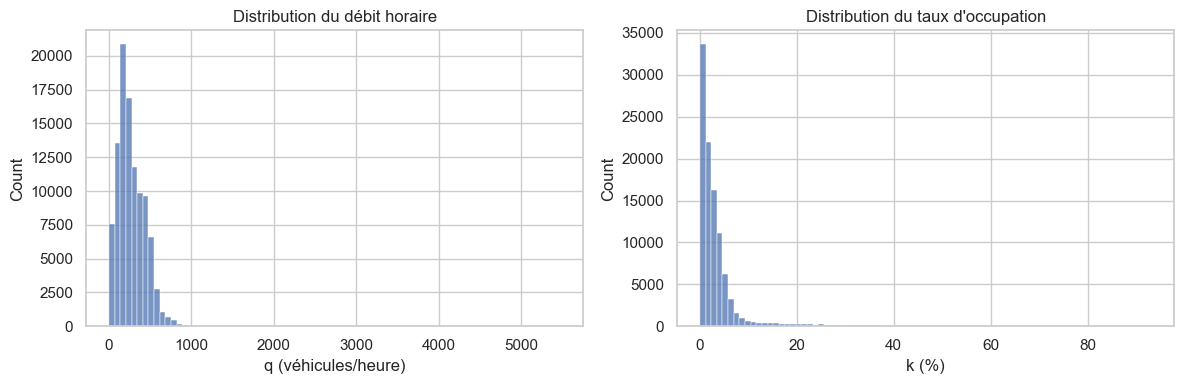

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["q"].dropna(), bins=80, ax=axes[0])
axes[0].set(title="Distribution du débit horaire", xlabel="q (véhicules/heure)")
sns.histplot(df["k"].dropna(), bins=80, ax=axes[1])
axes[1].set(title="Distribution du taux d'occupation", xlabel="k (%)")
plt.tight_layout()
plt.show()

In [14]:
q, k = df["q"].dropna(), df["k"].dropna()
print(f"Débit : médiane {q.median():.0f} véh/h, 95e percentile {q.quantile(.95):.0f}, max {q.max():.0f}.")
print(f"Occupation : médiane {k.median():.1f} %, 95e percentile {k.quantile(.95):.1f} %, max {k.max():.1f} %.")
print(f"{(df['q'] == 0).mean():.1%} des mesures de débit valent exactement 0.")

Débit : médiane 236 véh/h, 95e percentile 549, max 5479.
Occupation : médiane 2.1 %, 95e percentile 15.8 %, max 93.2 %.
0.0% des mesures de débit valent exactement 0.


**Comment lire :** un pic à gauche et une queue qui s'étire à droite signifient que la plupart des heures sont calmes et que quelques heures sont très chargées. Un pic isolé en 0 correspond à des heures sans véhicule ou à des capteurs coupés. Un maximum très éloigné du reste est suspect (voir M3).

> ✍️ **À écrire dans vos propres mots** : une phrase qui reprend les chiffres imprimés ci-dessus (médiane, 95e percentile, max).

### Graphique 2 : occupation selon l'état du trafic

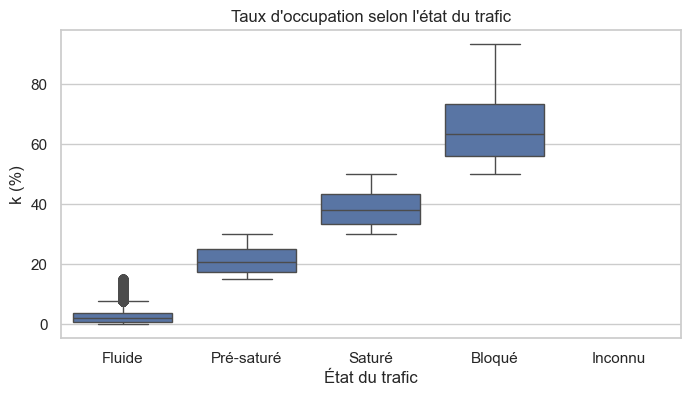

In [15]:
ordre = ["Fluide", "Pré-saturé", "Saturé", "Bloqué", "Inconnu"]
ordre = [o for o in ordre if o in df["etat_trafic"].cat.categories]
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="etat_trafic", y="k", order=ordre)
plt.title("Taux d'occupation selon l'état du trafic")
plt.xlabel("État du trafic"); plt.ylabel("k (%)")
plt.show()

In [16]:
print(df.groupby("etat_trafic", observed=True)["k"].agg(["count", "median", "min", "max"]).round(1))

             count  median   min   max
etat_trafic                           
Bloqué        1009    63.1  50.0  93.2
Fluide       97181     1.9   0.0  15.0
Inconnu          0     NaN   NaN   NaN
Pré-saturé    2875    20.7  15.0  30.0
Saturé        1500    38.0  30.0  50.0


**Comment lire :** si `k` augmente de *Fluide* à *Bloqué*, l'état du trafic est calculé à partir de l'occupation (c'est une variable *dérivée*, pas une mesure indépendante). Si la colonne `count` de `Inconnu` vaut 0, c'est que cet « état » correspond à une **absence de mesure**, pas à un état de trafic.

### Graphique 3 : débit moyen par tronçon

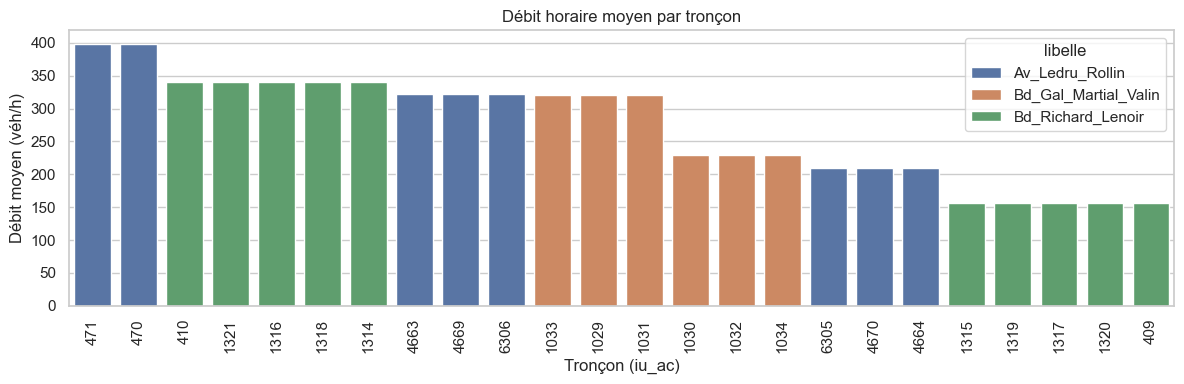

In [17]:
moy = (df.groupby(["libelle", "iu_ac"], observed=True)["q"].mean()
         .reset_index().sort_values("q", ascending=False))
plt.figure(figsize=(12, 4))
sns.barplot(data=moy, x="iu_ac", y="q", hue="libelle")
plt.xticks(rotation=90); plt.xlabel("Tronçon (iu_ac)"); plt.ylabel("Débit moyen (véh/h)")
plt.title("Débit horaire moyen par tronçon")
plt.tight_layout(); plt.show()

In [18]:
par_axe = moy.groupby("libelle", observed=True)["q"].agg(["mean", "min", "max"]).round(0)
print(par_axe)
top = moy.iloc[0]
print(f"Tronçon le plus chargé : {top['iu_ac']} ({top['libelle']}) avec {top['q']:.0f} véh/h en moyenne.")

                       mean    min    max
libelle                                  
Av_Ledru_Rollin       299.0  209.0  399.0
Bd_Gal_Martial_Valin  275.0  229.0  321.0
Bd_Richard_Lenoir     248.0  156.0  340.0
Tronçon le plus chargé : 471 (Av_Ledru_Rollin) avec 399 véh/h en moyenne.


**Comment lire :** les barres montrent à quel point deux tronçons d'un même axe peuvent différer (sens de circulation, nombre de voies, position dans l'axe). C'est pourquoi on calcule les statistiques **par tronçon** et pas seulement par axe.

## Bilan M1
- Format : séparateur `;`, encodage `utf-8-sig`, identifiants en `string`, états en `category`.
- Pièges repérés : valeurs manquantes (plus pour `k` que pour `q`), état `Inconnu`, valeurs extrêmes de `q`, doublons éventuels.
- Prochaine étape (`02_types_et_nettoyage.ipynb`) : dates et fuseau horaire, doublons, colonnes inutiles, valeurs manquantes.